# Baseline Unimodal — MVSA-Multiple (ALBERT)

**Model:** ALBERT-base-v2 (teks)
**Protokol:** 5-Fold Stratified Cross-Validation (seed 42) · Label majority-vote (Xu & Mao 2017)

**Pipeline:**
- Weighted Cross-Entropy (selalu dipakai; bobot dihitung dari label train tiap fold)
- Linear warmup (10%) + linear decay, di-step per batch
- Early stopping berdasarkan weighted F1 (patience 5); checkpoint terbaik tiap fold yang disimpan
- Metrik per epoch: loss, accuracy, weighted F1, macro F1
- Kurva training: Loss / Weighted F1 / Macro F1 / Accuracy (train vs val)

**Konfigurasi:** epoch 30 · batch 64 · LR teks 5e-5 · weight decay 1e-5.

File ini mandiri (tidak bergantung pada file model lain) dan hanya melatih model ALBERT (unimodal teks).

In [1]:
!pip install transformers --quiet

In [2]:
# -- Impor library ------------------------------------------------------------
# Pustaka umum: file, angka, tabel, dan visualisasi
import os, re, json, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

# PyTorch: model, dataset, loader, dan mixed precision (AMP)
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler

# Model teks (ALBERT) + scheduler warmup linear
from transformers import AlbertTokenizer, AlbertModel, get_linear_schedule_with_warmup

# Validasi silang + metrik evaluasi dari sklearn
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm  # progress bar per batch

print("All imports OK")

All imports OK


In [3]:
# -- Konfigurasi: dataclass agar rapi & mudah diubah -----------------------------------
# Seluruh notebook mengaksesnya sebagai Config.X (atribut kelas — tetap berfungsi).
from dataclasses import dataclass, field

@dataclass
class Config:
    # -- Path dataset cleaned ------------------------------------------------------------
    CLEANED_CSV: str = "/kaggle/input/datasets/azkurniwan/cleaned-mvsa-multiple/cleaned_MVSA/labelResult_cleaned.csv"
    IMAGE_DIR: str = "/kaggle/input/datasets/azkurniwan/cleaned-mvsa-multiple/cleaned_MVSA/data"
    ANNOTATION_FILE: str = CLEANED_CSV  # anotasi = CSV cleaned (format koma)
    CHECKPOINT_DIR: str = "/kaggle/working/checkpoints/unimodal/albert"  # output checkpoint & OOF
    PLOTS_DIR: str = "/kaggle/working/plots/unimodal/albert"  # output kurva training

    # -- Reprodusibilitas: seed dikunci agar split fold selalu sama -----------------------
    SEED: int = 42

    # -- Training --------------------------------------------------------------------------
    BATCH_SIZE: int = 64  # jumlah sampel per batch
    NUM_EPOCHS: int = 30  # epoch maksimum (early stopping bisa berhenti lebih awal)
    NUM_FOLDS: int = 5  # StratifiedKFold: tiap fold menjaga proporsi tiap kelas
    NUM_WORKERS: int = 0  # 0 agar tidak ada warning multiprocessing di Kaggle
    PIN_MEMORY: bool = False  # hanya berguna jika num_workers > 0

    # -- Early stopping: berhenti bila weighted F1 val tak membaik 5 epoch ----------------
    PATIENCE: int = 5  # memantau weighted F1 (bukan loss)

    # -- Teks (ALBERT) -----------------------------------------------------------------------
    ALBERT_MODEL: str = "albert-base-v2"  # checkpoint Hugging Face
    MAX_SEQ_LEN: int = 128  # panjang token maksimum (padding/truncation)
    LR_TEXT: float = 5e-5  # learning rate khusus model teks
    WARMUP_RATIO: float = 0.1  # 10% total step dipakai untuk linear warmup

    # -- Gambar --------------------------------------------------------------------------------
    LR_IMAGE: float = 1e-4  # learning rate khusus model gambar
    IMG_SIZE_MOBILENETV3: int = 224  # resolusi input MobileNetV3
    IMG_SIZE_MOBILEVIT: int = 256  # resolusi input MobileViT

    # -- Optimizer: weight decay sebagai regularisasi AdamW -------------------------------------
    WEIGHT_DECAY: float = 1e-5

    # -- Kelas sentimen (dict wajib memakai default_factory menurut aturan dataclass) -----------
    LABEL2ID: dict = field(default_factory=lambda: {"positive": 0, "neutral": 1, "negative": 2})
    ID2LABEL: dict = field(default_factory=lambda: {0: "positive", 1: "neutral", 2: "negative"})
    NUM_CLASSES: int = 3

    # -- Perangkat: GPU bila tersedia, jika tidak memakai CPU --------------------------------------
    DEVICE: object = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Kompatibilitas: field dict memakai default_factory sehingga atribut kelasnya terhapus;
# pasang ulang agar Config.LABEL2ID / Config.ID2LABEL tetap bisa diakses seperti semula.
Config.LABEL2ID = {"positive": 0, "neutral": 1, "negative": 2}
Config.ID2LABEL = {0: "positive", 1: "neutral", 2: "negative"}


def set_seed(seed):
    # Kunci semua sumber acak agar hasil eksperimen dapat direproduksi
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

set_seed(Config.SEED)
# Buat folder checkpoint dan gambar kurva bila belum ada
os.makedirs(Config.CHECKPOINT_DIR, exist_ok=True)
os.makedirs(Config.PLOTS_DIR, exist_ok=True)
print(f"Device : {Config.DEVICE}")
print(f"Seed   : {Config.SEED}")


Device : cuda
Seed   : 42


In [4]:
# ============================================================
# Bootstrap checkpoint dari commit sebelumnya
# ------------------------------------------------------------
import shutil

def find_and_copy_checkpoints(dest_dir, search_root="/kaggle/input"):
    os.makedirs(dest_dir, exist_ok=True)
    found_files = []
    for root, dirs, files in os.walk(search_root):
        for fn in files:
            if fn.endswith(".pt") or fn.endswith("_oof.json") or fn == "unimodal_results.json":
                found_files.append(os.path.join(root, fn))
    if not found_files:
        print(f"[Bootstrap] Tidak ditemukan checkpoint di {search_root}.")
        print("[Bootstrap] Training akan berjalan dari awal untuk semua fold.")
        return 0
    n = 0
    for f in found_files:
        try:
            shutil.copy(f, dest_dir)
            n += 1
        except Exception as e:
            print(f"[Bootstrap] Gagal menyalin {f}: {e}")
    print(f"[Bootstrap] {n} file checkpoint berhasil disalin ke {dest_dir}")
    return n

_n_copied = find_and_copy_checkpoints(Config.CHECKPOINT_DIR)
if _n_copied > 0:
    print("[Bootstrap] Fold dengan checkpoint FINAL lengkap akan otomatis DILEWATI (skip training, hemat waktu).")


[Bootstrap] Tidak ditemukan checkpoint di /kaggle/input.
[Bootstrap] Training akan berjalan dari awal untuk semua fold.


In [5]:
# -- Preprocessing data cleaned (format CSV cleaned) -----------------------------------
# Format labelResult_cleaned.csv: ID, text_label, image_label, final_label.
# Tiap sel berisi SATU label (sudah majority vote + resolusi polaritas Xu & Mao 2017),

from collections import Counter

# -- Normalisasi label --
LABEL_NORM = {
    'positive': 'positive', 'pos': 'positive',
    'neutral':  'neutral',  'neu': 'neutral',
    'negative': 'negative', 'neg': 'negative',
}

VALID_LABELS = {'positive', 'neutral', 'negative'}


def norm_label(value):
    # Normalisasi satu label menjadi bentuk baku; None bila tak dikenal/kosong.
    if value is None:
        return None
    s = str(value).strip().lower()
    return LABEL_NORM.get(s) if s else None


def resolve_polarity(text_label, image_label):
    # Aturan Xu & Mao (2017), dipakai untuk CEK konsistensi kolom final_label:
    # - Sama -> ikuti
    # - Salah satu netral -> ikuti yang polar
    # - Positif vs Negatif -> 'conflict' (seharusnya sudah dibuang di file cleaned)
    if text_label == image_label:
        return text_label
    if text_label == 'neutral':
        return image_label
    if image_label == 'neutral':
        return text_label
    return 'conflict'


def clean_text(text):
    # Bersihkan teks tweet: hapus RT/mention/URL, ubah hashtag, buang non-ASCII.
    text = re.sub(r'\bRT\b\s*@\w+:?\s*', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'#(\w+)', r'\1', text)
    text = re.sub(r'[^\x00-\x7F]+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()


def load_data():
    # -- 1. Baca anotasi cleaned --
    print("Loading annotations...")
    print(f"  File: {Config.ANNOTATION_FILE}")
    # Separator otomatis dari isi baris header (koma -> CSV cleaned, tab -> TXT asli)
    with open(Config.ANNOTATION_FILE, 'r', encoding='utf-8', errors='ignore') as _fh:
        _header = _fh.readline()
    _n_comma, _n_tab = _header.count(','), _header.count('\t')
    if max(_n_comma, _n_tab) == 0:
        raise ValueError(f"Separator tak dikenal. Header: {_header.strip()[:120]}")
    sep = ',' if _n_comma >= _n_tab else '\t'
    print(f"  Separator terdeteksi: {'koma (CSV)' if sep == ',' else 'tab (TXT)'}")
    raw_df = pd.read_csv(Config.ANNOTATION_FILE, sep=sep)
    raw_df.columns = [str(c).strip() for c in raw_df.columns]  # buang spasi nama kolom

    # Samakan nama kolom ID (tak peduli huruf besar/kecil)
    id_col = next((c for c in raw_df.columns if c.lower() == 'id'), None)
    if id_col is None:
        raise ValueError(f"Kolom ID tidak ditemukan. Kolom tersedia: {list(raw_df.columns)}")
    raw_df = raw_df.rename(columns={id_col: 'ID'})

    # Wajib ada 3 kolom label format cleaned; gagal cepat dengan pesan jelas
    need = ['text_label', 'image_label', 'final_label']
    miss = [c for c in need if c not in raw_df.columns]
    if miss:
        raise ValueError(f"Kolom {miss} tidak ditemukan (format cleaned: ID,text_label,image_label,final_label). "
                         f"Kolom tersedia: {list(raw_df.columns)}")
    n_raw = len(raw_df)
    print(f"  [1] Total data asli (raw)         : {n_raw}")

    # -- 2. Normalisasi label & buang baris berlabel asing --
    for c in need:
        raw_df[c] = raw_df[c].apply(norm_label)
    bad = raw_df[need].isna().any(axis=1).sum()
    print(f"  [2] Baris berlabel asing/kosong   : {bad}")
    df = raw_df.dropna(subset=need).copy()
    df.reset_index(drop=True, inplace=True)
    print(f"  [3] Setelah buang label asing     : {len(df)}")

    # -- 3. Cek konsistensi final_label terhadap aturan Xu & Mao --
    recalc = df.apply(lambda r: resolve_polarity(r['text_label'], r['image_label']), axis=1)
    n_mismatch = (recalc != df['final_label']).sum()
    n_conflict = (df['final_label'] == 'conflict').sum()
    print(f"  [4] final tak konsisten (cek)     : {n_mismatch}")
    print(f"  [5] Konflik polar (pos vs neg)    : {n_conflict}")
    if n_mismatch:
        print("  Peringatan: ada final_label menyimpang dari aturan — dipakai apa adanya dari file.")

    # -- 4. Muat teks dari file --
    print("Loading texts...")
    texts = {}
    n_missing_txt = 0
    for sid in tqdm(df['ID'].astype(str), desc="txt", leave=False):
        p = os.path.join(Config.IMAGE_DIR, f"{sid}.txt")
        if os.path.exists(p):
            with open(p, 'r', encoding='utf-8', errors='ignore') as f:
                texts[sid] = clean_text(f.read())
        else:
            texts[sid] = ""
            n_missing_txt += 1
    print(f"  [6] File .txt tidak ditemukan     : {n_missing_txt}")

    df['id'] = df['ID'].astype(str)
    df['text'] = df['id'].map(texts)
    n_empty_text = (df['text'] == "").sum()
    print(f"  [7] Teks kosong setelah cleaning  : {n_empty_text}")

    df = df[df['text'] != ""].reset_index(drop=True)
    df['label'] = df['final_label'].map(Config.LABEL2ID)

    print(f"\n  [8] TOTAL AKHIR                   : {len(df)}")
    print(f"\n  Distribusi label akhir:")
    print(df['final_label'].value_counts().to_string())

    # Tabel persentase
    print(f"\n  {'Label':<12} {'Jumlah':>8} {'Persentase':>12}")
    print("  " + "-" * 34)
    for label in ['positive', 'neutral', 'negative']:
        count = (df['final_label'] == label).sum()
        pct = count / len(df) * 100 if len(df) else 0.0
        print(f"  {label:<12} {count:>8} {pct:>11.1f}%")
    print("  " + "-" * 34)
    print(f"  {'TOTAL':<12} {len(df):>8}")

    return df


df = load_data()

Loading annotations...
  File: /kaggle/input/datasets/azkurniwan/cleaned-mvsa-multiple/cleaned_MVSA/labelResult_cleaned.csv
  Separator terdeteksi: koma (CSV)
  [1] Total data asli (raw)         : 17024
  [2] Baris berlabel asing/kosong   : 0
  [3] Setelah buang label asing     : 17024
  [4] final tak konsisten (cek)     : 0
  [5] Konflik polar (pos vs neg)    : 0
Loading texts...


txt:   0%|          | 0/17024 [00:00<?, ?it/s]

  [6] File .txt tidak ditemukan     : 0
  [7] Teks kosong setelah cleaning  : 0

  [8] TOTAL AKHIR                   : 17024

  Distribusi label akhir:
final_label
positive    11318
neutral      4408
negative     1298

  Label          Jumlah   Persentase
  ----------------------------------
  positive        11318        66.5%
  neutral          4408        25.9%
  negative         1298         7.6%
  ----------------------------------
  TOTAL           17024


In [6]:
# -- Dataset untuk teks -----------------------------------------------------------
# TextDataset: tokenisasi teks memakai tokenizer ALBERT (panjang seragam)

class TextDataset(Dataset):
    def __init__(self, df, tokenizer, max_len):
        self.texts     = df['text'].tolist()   # daftar teks
        self.labels    = df['label'].tolist()  # daftar label (0/1/2)
        self.tokenizer = tokenizer
        self.max_len   = max_len               # panjang token maksimum

    def __len__(self):  return len(self.labels)

    def __getitem__(self, idx):
        # Tokenisasi satu teks menjadi input_ids + attention_mask sepanjang max_len
        enc = self.tokenizer(self.texts[idx],
                             max_length=self.max_len,
                             padding='max_length',
                             truncation=True,
                             return_tensors='pt')
        return {'input_ids':      enc['input_ids'].squeeze(0),
                'attention_mask': enc['attention_mask'].squeeze(0),
                'label':          torch.tensor(self.labels[idx], dtype=torch.long)}

print("Dataset classes defined.")

Dataset classes defined.


In [7]:
# -- Definisi model ----------------------------------------------------------------
# TextClassifier: ALBERT + MLP 2 lapis (hidden -> 256 -> 3 kelas)

class TextClassifier(nn.Module):
    def __init__(self, num_classes, dropout=0.3):
        super().__init__()
        self.albert     = AlbertModel.from_pretrained(Config.ALBERT_MODEL)
        hidden          = self.albert.config.hidden_size  # 768 untuk albert-base-v2
        # Kepala klasifikasi: Linear-ReLU-Dropout-Linear
        self.classifier = nn.Sequential(
            nn.Linear(hidden, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, num_classes))

    def forward(self, input_ids, attention_mask):
        out = self.albert(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0, :]  # ambil embedding token pertama ([CLS])
        return self.classifier(cls)

print("Model classes defined.")

Model classes defined.


In [8]:
# -- Fungsi bantu training & evaluasi (pipeline disamakan) ----------------------------
# - get_loss_fn        : Weighted Cross-Entropy, SELALU dipakai
#                        (bobot dihitung dari label train pada fold yang berjalan)
# - train_one_epoch    : 1 epoch training; mengembalikan loss, weighted F1,
#                        macro F1, accuracy (inilah 4 metrik yang tampil per epoch)
# - evaluate           : evaluasi validasi; menghitung 8 metrik lengkap, tetapi
#                        yang ditampilkan per epoch hanya loss/accuracy/weighted F1/
#                        macro F1 (precision/recall hanya untuk hasil akhir)
# - collect_predictions: kumpulkan prediksi checkpoint terbaik untuk agregasi OOF
# - compute_oof_report : confusion matrix + classification report SEKALI untuk
#                        seluruh dataset (bukan rata-rata antar fold)
# - print_summary      : rata-rata +- std antar fold (hasil akhir, 8 metrik)
# - plot_loss_curve    : 4 kurva train-vs-val (Loss, Weighted F1, Macro F1, Accuracy)

def get_loss_fn(labels, device):
    # Hitung sebaran kelas pada fold ini (hanya untuk info di log)
    counts = np.bincount(np.asarray(labels), minlength=Config.NUM_CLASSES)
    # Bobot seimbang: kelas minoritas diberi bobot lebih besar
    w = compute_class_weight('balanced',
                             classes=np.arange(Config.NUM_CLASSES),
                             y=np.asarray(labels))
    w = torch.tensor(w, dtype=torch.float).to(device)
    print(f"  Class counts: {counts} | weights={w.cpu().numpy().round(3)}")
    print("  -> Weighted CrossEntropy (selalu dipakai)")
    return nn.CrossEntropyLoss(weight=w)


def train_one_epoch(model, loader, optimizer, criterion, scaler, device, is_text, scheduler=None):
    model.train()  # mode training (dropout aktif)
    total_loss, preds, labels_all = 0.0, [], []
    for batch in tqdm(loader, desc="    Train", leave=False):
        optimizer.zero_grad()  # nolkan gradien dari batch sebelumnya
        with autocast():  # mixed precision: hemat memori & percepat training
            if is_text:  # cabang teks: forward ALBERT
                logits = model(batch['input_ids'].to(device),
                               batch['attention_mask'].to(device))
            else:  # cabang gambar: forward encoder CNN/ViT
                logits = model(batch['image'].to(device))
            lbl  = batch['label'].to(device)
            loss = criterion(logits, lbl)  # weighted cross-entropy
        scaler.scale(loss).backward()  # backprop (diskalakan agar stabil di AMP)
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # cegah ledakan gradien
        scaler.step(optimizer); scaler.update()
        if scheduler is not None:  # scheduler linear di-step PER BATCH (teks & gambar sama)
            scheduler.step()
        total_loss += loss.item()
        preds.extend(logits.argmax(-1).cpu().numpy())  # kumpulkan prediksi batch ini
        labels_all.extend(lbl.cpu().numpy())  # kumpulkan label aslinya
    # Metrik train per epoch: hanya loss, weighted F1, macro F1, accuracy
    avg_loss = total_loss / len(loader)
    acc = accuracy_score(labels_all, preds)
    f1w = f1_score(labels_all, preds, average='weighted', zero_division=0)
    f1m = f1_score(labels_all, preds, average='macro', zero_division=0)
    return avg_loss, f1w, f1m, acc


@torch.no_grad()
def evaluate(model, loader, criterion, device, is_text):
    # Evaluasi validasi tanpa gradien. Menghitung 8 metrik lengkap:
    # loss & accuracy (dipertahankan), f1 = weighted F1 (untuk early stopping),
    # precision/recall weighted & macro (hanya dipakai di hasil akhir/OOF).
    model.eval()  # mode evaluasi (dropout mati)
    total_loss, preds, labels_all = 0.0, [], []
    for batch in tqdm(loader, desc="    Val  ", leave=False):
        with autocast():
            if is_text:  # cabang teks
                logits = model(batch['input_ids'].to(device),
                               batch['attention_mask'].to(device))
            else:  # cabang gambar
                logits = model(batch['image'].to(device))
            lbl  = batch['label'].to(device)
            loss = criterion(logits, lbl)
        total_loss += loss.item()
        preds.extend(logits.argmax(-1).cpu().numpy())
        labels_all.extend(lbl.cpu().numpy())
    return {'loss':               total_loss / len(loader),
            'accuracy':           accuracy_score(labels_all, preds),
            'precision_weighted': precision_score(labels_all, preds, average='weighted', zero_division=0),
            'recall_weighted':    recall_score(labels_all, preds, average='weighted', zero_division=0),
            'f1':                 f1_score(labels_all, preds, average='weighted', zero_division=0),
            'precision_macro':    precision_score(labels_all, preds, average='macro', zero_division=0),
            'recall_macro':       recall_score(labels_all, preds, average='macro', zero_division=0),
            'f1_macro':           f1_score(labels_all, preds, average='macro', zero_division=0)}


@torch.no_grad()
def collect_predictions(model, loader, device, is_text):
    # Kumpulkan (prediksi, label) dari loader validasi memakai checkpoint TERBAIK.
    # Dipakai untuk agregasi OOF; BUKAN model epoch terakhir.
    model.eval()
    preds, labels_all = [], []
    for batch in tqdm(loader, desc='    OOF  ', leave=False):
        with autocast():
            if is_text:
                logits = model(batch['input_ids'].to(device),
                               batch['attention_mask'].to(device))
            else:
                logits = model(batch['image'].to(device))
        preds.extend(logits.argmax(-1).cpu().numpy())
        labels_all.extend(batch['label'].numpy())
    return np.asarray(preds), np.asarray(labels_all)


def compute_oof_report(oof_labels, oof_preds, exp_name):
    # Hitung SEKALI di atas gabungan seluruh fold (mencakup seluruh dataset,
    # karena set validasi tiap fold saling lepas) — bukan rata-rata antar fold.
    labels_order = [Config.LABEL2ID['positive'], Config.LABEL2ID['neutral'], Config.LABEL2ID['negative']]
    target_names = [Config.ID2LABEL[i] for i in labels_order]
    cm = confusion_matrix(oof_labels, oof_preds, labels=labels_order)  # matriks 3x3
    rep = classification_report(oof_labels, oof_preds, labels=labels_order,
                                target_names=target_names, output_dict=True, zero_division=0)
    # Simpan hasil OOF ke file JSON terpisah per eksperimen
    out_path = os.path.join(Config.CHECKPOINT_DIR, f'{exp_name}_oof.json')
    with open(out_path, 'w') as f:
        json.dump({'confusion_matrix': cm.tolist(),
                   'classification_report': rep,
                   'target_names': target_names}, f, indent=2)
    # Tampilkan ringkas di notebook
    print(f'\n  [OOF] {exp_name}: N={len(oof_labels)} | saved: {out_path}')
    print('  [OOF] Confusion matrix (baris=true, kolom=prediksi | positive, neutral, negative):')
    print('  ' + str(cm).replace(chr(10), chr(10) + '  '))
    print('  [OOF] Laporan per kelas:')
    print(f"  {'class':<10}{'prec':>8}{'rec':>8}{'f1':>8}{'sup':>8}")
    for c in target_names:  # satu baris per kelas sentimen
        r = rep[c]
        print(f"  {c:<10}{r['precision']:>8.4f}{r['recall']:>8.4f}{r['f1-score']:>8.4f}{r['support']:>8.0f}")
    for k in ['macro avg', 'weighted avg', 'accuracy']:  # baris rangkuman
        r = rep[k] if k in rep else None
        if isinstance(r, dict):
            print(f"  {k:<10}{r['precision']:>8.4f}{r['recall']:>8.4f}{r['f1-score']:>8.4f}{r['support']:>8.0f}")
        else:
            print(f"  {k:<10}{'':>8}{'':>8}{r:>8.4f}{'':>8}")
    return {'confusion_matrix': cm, 'report': rep, 'oof_path': out_path}


def print_summary(fold_results, exp_name):
    # Hasil akhir: rata-rata +- std antar fold untuk 8 metrik
    # (precision/recall — weighted & macro — tampil di sini, bukan per epoch).
    print(f"\n{'='*55}\nSUMMARY: {exp_name}\n{'='*55}")
    for m in ['loss','accuracy','precision_weighted','recall_weighted','f1',
              'precision_macro','recall_macro','f1_macro']:
        v = [r[m] for r in fold_results]
        print(f'  {m:20s}: {np.mean(v):.4f} +- {np.std(v):.4f}')


def plot_loss_curve(history, exp_name, fold_num):
    # 4 subplot sejajar: Loss, Weighted F1, Macro F1, Accuracy (train vs val per epoch).
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 4, figsize=(24, 4))

    axes[0].plot(epochs, history['train_loss'], 'o-', label='Train Loss', color='steelblue')
    axes[0].plot(epochs, history['val_loss'],   'o-', label='Val Loss',   color='firebrick')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
    axes[0].set_title(f'{exp_name} Fold {fold_num} — Loss')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, history['train_f1'], 'o-', label='Train F1', color='steelblue')
    axes[1].plot(epochs, history['val_f1'],   'o-', label='Val F1',   color='firebrick')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Weighted F1')
    axes[1].set_title(f'{exp_name} Fold {fold_num} — Weighted F1')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    axes[2].plot(epochs, history['train_f1_macro'], 'o-', label='Train Macro F1', color='steelblue')
    axes[2].plot(epochs, history['val_f1_macro'],   'o-', label='Val Macro F1',   color='firebrick')
    axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Macro F1')
    axes[2].set_title(f'{exp_name} Fold {fold_num} — Macro F1')
    axes[2].legend(); axes[2].grid(alpha=0.3)

    axes[3].plot(epochs, history['train_acc'], 'o-', label='Train Acc', color='steelblue')
    axes[3].plot(epochs, history['val_acc'],   'o-', label='Val Acc',   color='firebrick')
    axes[3].set_xlabel('Epoch'); axes[3].set_ylabel('Accuracy')
    axes[3].set_title(f'{exp_name} Fold {fold_num} — Accuracy')
    axes[3].legend(); axes[3].grid(alpha=0.3)

    plt.tight_layout()
    save_path = os.path.join(Config.PLOTS_DIR, f'{exp_name}_fold{fold_num}_curves.png')
    plt.savefig(save_path, dpi=100, bbox_inches='tight')
    plt.show()
    plt.close()

print("Helpers defined.")

Helpers defined.


In [9]:
# -- E1: 5-Fold CV — ALBERT (unimodal teks) -----------------------------------------
# - Scheduler: linear warmup (10%) + linear decay, di-step per batch
# - Loss: weighted CE (selalu); seleksi model & early stopping: weighted F1
# - OOF: prediksi tiap fold memakai checkpoint TERBAIK (bukan epoch terakhir)
# - Log per epoch: hanya loss, weighted F1, macro F1, accuracy
# - Checkpoint in-progress per epoch + resume otomatis bila kernel restart

def run_cv_text(df, exp_name='ALBERT_unimodal'):
    print(f"\n{'='*55}\nEXP: {exp_name}\n{'='*55}")
    tokenizer    = AlbertTokenizer.from_pretrained(Config.ALBERT_MODEL)
    # StratifiedKFold: tiap fold menjaga proporsi kelas (seed terkunci)
    skf          = StratifiedKFold(n_splits=Config.NUM_FOLDS, shuffle=True,
                                   random_state=Config.SEED)
    fold_results = []  # metrik terbaik tiap fold (untuk rata-rata +- std)
    oof_preds_list, oof_labels_list = [], []  # prediksi OOF per fold

    for fold, (tr_idx, va_idx) in enumerate(skf.split(df, df['label'])):
        print(f'\n  Fold {fold+1}/{Config.NUM_FOLDS}')
        ckpt = os.path.join(Config.CHECKPOINT_DIR, f'{exp_name}_fold{fold+1}.pt')
        # Checkpoint mid-fold: ditimpa tiap epoch, dihapus saat final tersimpan (hemat disk)
        ckpt_inprogress = os.path.join(Config.CHECKPOINT_DIR, f'{exp_name}_fold{fold+1}_inprogress.pt')
        # Bagi data fold ini menjadi train dan validasi (saling lepas)
        tr_df = df.iloc[tr_idx].reset_index(drop=True)
        va_df = df.iloc[va_idx].reset_index(drop=True)
        tr_loader = DataLoader(TextDataset(tr_df, tokenizer, Config.MAX_SEQ_LEN),
                               batch_size=Config.BATCH_SIZE, shuffle=True,
                               num_workers=Config.NUM_WORKERS, pin_memory=Config.PIN_MEMORY)
        va_loader = DataLoader(TextDataset(va_df, tokenizer, Config.MAX_SEQ_LEN),
                               batch_size=Config.BATCH_SIZE, shuffle=False,
                               num_workers=Config.NUM_WORKERS, pin_memory=Config.PIN_MEMORY)
        # Model, optimizer (LR teks), loss (bobot dari label train fold ini), scaler AMP
        model     = TextClassifier(Config.NUM_CLASSES).to(Config.DEVICE)
        optimizer = torch.optim.AdamW(model.parameters(), lr=Config.LR_TEXT,
                                      weight_decay=Config.WEIGHT_DECAY)
        criterion = get_loss_fn(tr_df['label'].values, Config.DEVICE)
        scaler    = GradScaler()
        # Scheduler linear: 10% step awal warmup, sisanya decay linear
        total_steps  = len(tr_loader) * Config.NUM_EPOCHS
        warmup_steps = int(total_steps * Config.WARMUP_RATIO)
        scheduler    = get_linear_schedule_with_warmup(
            optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)

        if os.path.exists(ckpt):
            # Fold sudah pernah dilatih: muat ulang agar tidak melatih ulang
            d = torch.load(ckpt, map_location='cpu')
            if 'oof_preds' in d and 'oof_labels' in d:
                fold_results.append(d['val_metrics'])
                oof_preds_list.append(np.asarray(d['oof_preds']))
                oof_labels_list.append(np.asarray(d['oof_labels']))
                print(f"  Loaded from checkpoint — F1: {d['val_metrics']['f1']:.4f} (with OOF)")
                print(f"  Skenario: FINAL sudah ada -> fold {fold+1} dilewati.")
                history = d.get('history', None)  # kompatibel checkpoint FINAL lama tanpa history
                if history is not None:
                    try:
                        plot_loss_curve(history, exp_name, fold+1)  # tampilkan ulang kurva dari FINAL
                    except Exception as e:
                        print(f"  [Info] Gagal plot history dari checkpoint: {e}")
                else:
                    print("  [Info] history tidak tersedia di checkpoint FINAL lama — grafik dilewati.")
                if os.path.exists(ckpt_inprogress):
                    os.remove(ckpt_inprogress)  # sisa in-progress tak diperlukan lagi
                del model, optimizer, criterion, scaler
                torch.cuda.empty_cache()
                continue
            # Checkpoint lama tanpa OOF: hitung OOF dari bobot tersimpan, lalu lengkapi file
            print('  Checkpoint found but missing OOF — re-running fold to collect OOF...')
            try: model.load_state_dict(d['model_state'])
            except Exception: pass
            model.to(Config.DEVICE)
            fp, fl = collect_predictions(model, va_loader, Config.DEVICE, is_text=True)
            _old_hist = d.get('history', None)  # pertahankan history bila FINAL lama sudah memilikinya
            d = {'fold': fold+1, 'val_metrics': d['val_metrics'],
                 'model_state': copy.deepcopy(model.state_dict()),
                 'oof_preds': fp.tolist(), 'oof_labels': fl.tolist(),
                 'history': _old_hist}
            torch.save(d, ckpt)
            if os.path.exists(ckpt_inprogress):
                os.remove(ckpt_inprogress)  # final (legacy) sudah lengkap
            fold_results.append(d['val_metrics'])
            oof_preds_list.append(fp); oof_labels_list.append(fl)
            del model, optimizer, criterion, scaler
            torch.cuda.empty_cache()
            continue

        # Skenario (b): resume mid-fold — timpa state fresh dengan checkpoint in-progress.
        # State RNG ikut dipulihkan agar urutan batch & dropout identik seperti tanpa restart.
        # Skenario (c): fold baru — mulai dari epoch 0 dengan pelacakan fresh.
        if os.path.exists(ckpt_inprogress):
            d = torch.load(ckpt_inprogress, map_location=Config.DEVICE)
            model.load_state_dict(d['model_state'])
            optimizer.load_state_dict(d['optimizer_state'])
            scheduler.load_state_dict(d['scheduler_state'])
            scaler.load_state_dict(d['scaler_state'])
            random.setstate(d['rng_states']['python'])
            np.random.set_state(d['rng_states']['numpy'])
            torch.set_rng_state(d['rng_states']['torch_cpu'])
            if torch.cuda.is_available() and d['rng_states']['torch_cuda'] is not None:
                torch.cuda.set_rng_state_all(d['rng_states']['torch_cuda'])
            start_epoch = d['epoch'] + 1  # lanjut dari epoch BERIKUTNYA
            best_f1, best_met, best_state = d['best_f1'], d['best_met'], d['best_state']
            patience_ctr, history = d['patience_ctr'], d['history']
            print(f"  Resume fold {fold+1} dari epoch {start_epoch+1} (in-progress checkpoint ditemukan)")
        else:
            start_epoch = 0
            print(f"  Fold baru: mulai dari epoch 1")
            # Pelacakan model terbaik (berdasarkan weighted F1 validasi)
            best_f1, best_met, best_state, patience_ctr = 0.0, {}, None, 0
            # Riwayat kurva: hanya loss, weighted F1, macro F1, accuracy
            history = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'val_f1': [],
                       'train_f1_macro': [], 'val_f1_macro': [],
                       'train_acc': [], 'val_acc': []}
        for ep in range(start_epoch, Config.NUM_EPOCHS):  # lanjut dari resume bila ada
            # 1 epoch training (scheduler ikut step per batch di dalamnya)
            tr_loss, tr_f1, tr_f1m, tr_acc = train_one_epoch(model, tr_loader, optimizer,
                                              criterion, scaler, Config.DEVICE,
                                              is_text=True, scheduler=scheduler)
            # Evaluasi validasi epoch ini
            val_met        = evaluate(model, va_loader, criterion, Config.DEVICE, is_text=True)
            val_met_loss, val_met_f1, val_met_f1m, val_met_acc = val_met['loss'], val_met['f1'], val_met['f1_macro'], val_met['accuracy']
            # Simpan riwayat untuk kurva
            history['train_loss'].append(tr_loss)
            history['val_loss'].append(val_met['loss'])
            history['train_f1'].append(tr_f1)
            history['val_f1'].append(val_met['f1'])
            history['train_f1_macro'].append(tr_f1m)
            history['val_f1_macro'].append(val_met['f1_macro'])
            history['train_acc'].append(tr_acc)
            history['val_acc'].append(val_met['accuracy'])
            # Log per epoch: hanya loss, weighted F1, macro F1, accuracy
            print(f"    Ep {ep+1:2d} | TrLoss {tr_loss:.4f} TrF1 {tr_f1:.4f} TrMacro {tr_f1m:.4f} TrAcc {tr_acc:.4f} "
                  f"| ValLoss {val_met_loss:.4f} ValF1 {val_met_f1:.4f} ValMacro {val_met_f1m:.4f} ValAcc {val_met_acc:.4f}")
            # Bandingkan weighted F1: simpan yang terbaik, hitung kesabaran bila memburuk
            if val_met['f1'] > best_f1:
                best_f1, best_met = val_met['f1'], val_met.copy()
                best_state = copy.deepcopy(model.state_dict())  # salin bobot terbaik
                patience_ctr = 0  # ada perbaikan: hitungan kesabaran dinolkan
            else:
                patience_ctr += 1
                if patience_ctr >= Config.PATIENCE:
                    print(f'    Early stopping at epoch {ep+1} (patience={Config.PATIENCE})')
                    break
            # Simpan state mid-fold setiap epoch rampung (timpa file yang sama agar hemat disk).
            # Epoch pemicu early-stop tak perlu disimpan (fold langsung difinalkan di bawah).
            torch.save({
                'epoch': ep, 'model_state': model.state_dict(),
                'optimizer_state': optimizer.state_dict(),
                'scheduler_state': scheduler.state_dict(),
                'scaler_state': scaler.state_dict(),
                'rng_states': {'python': random.getstate(), 'numpy': np.random.get_state(),
                               'torch_cpu': torch.get_rng_state(),
                               'torch_cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None},
                'best_f1': best_f1, 'best_met': best_met, 'best_state': best_state,
                'patience_ctr': patience_ctr, 'history': history,
            }, ckpt_inprogress)
        # OOF memakai bobot TERBAIK (bukan epoch terakhir)
        model.load_state_dict(best_state)
        fold_preds, fold_labels = collect_predictions(model, va_loader, Config.DEVICE, is_text=True)
        oof_preds_list.append(fold_preds); oof_labels_list.append(fold_labels)
        fold_results.append(best_met)
        # Simpan checkpoint FINAL + history (untuk plot ulang tanpa retraining)
        torch.save({'fold': fold+1, 'val_metrics': best_met, 'model_state': best_state,
                    'oof_preds': fold_preds.tolist(), 'oof_labels': fold_labels.tolist(),
                    'history': history}, ckpt)
        # Fold selesai & final tersimpan: hapus in-progress (tak diperlukan lagi)
        if os.path.exists(ckpt_inprogress):
            os.remove(ckpt_inprogress)
        print(f'  Best F1: {best_f1:.4f} | Saved.')
        plot_loss_curve(history, exp_name, fold+1)  # gambar 4 kurva fold ini
        del model, optimizer, criterion, scaler  # bebaskan memori GPU
        torch.cuda.empty_cache()

    print_summary(fold_results, exp_name)  # rata-rata +- std antar fold (8 metrik)
    # Gabung OOF seluruh fold → satu array (mencakup seluruh dataset)
    oof_preds  = np.concatenate(oof_preds_list)
    oof_labels = np.concatenate(oof_labels_list)
    oof = compute_oof_report(oof_labels, oof_preds, exp_name)
    oof['preds'], oof['labels'] = oof_preds, oof_labels
    return fold_results, oof

print("run_cv_text defined.")

run_cv_text defined.



EXP: ALBERT_unimodal


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/760k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


  Fold 1/5


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

... (38 outputs left out)

    Val  :   0%|          | 0/54 [00:00<?, ?it/s]

    Ep 12 | TrLoss 0.1690 TrF1 0.9261 TrMacro 0.9170 TrAcc 0.9248 | ValLoss 1.9099 ValF1 0.6287 ValMacro 0.5150 ValAcc 0.6173
    Early stopping at epoch 12 (patience=5)


    OOF  :   0%|          | 0/54 [00:00<?, ?it/s]

  Best F1: 0.6456 | Saved.


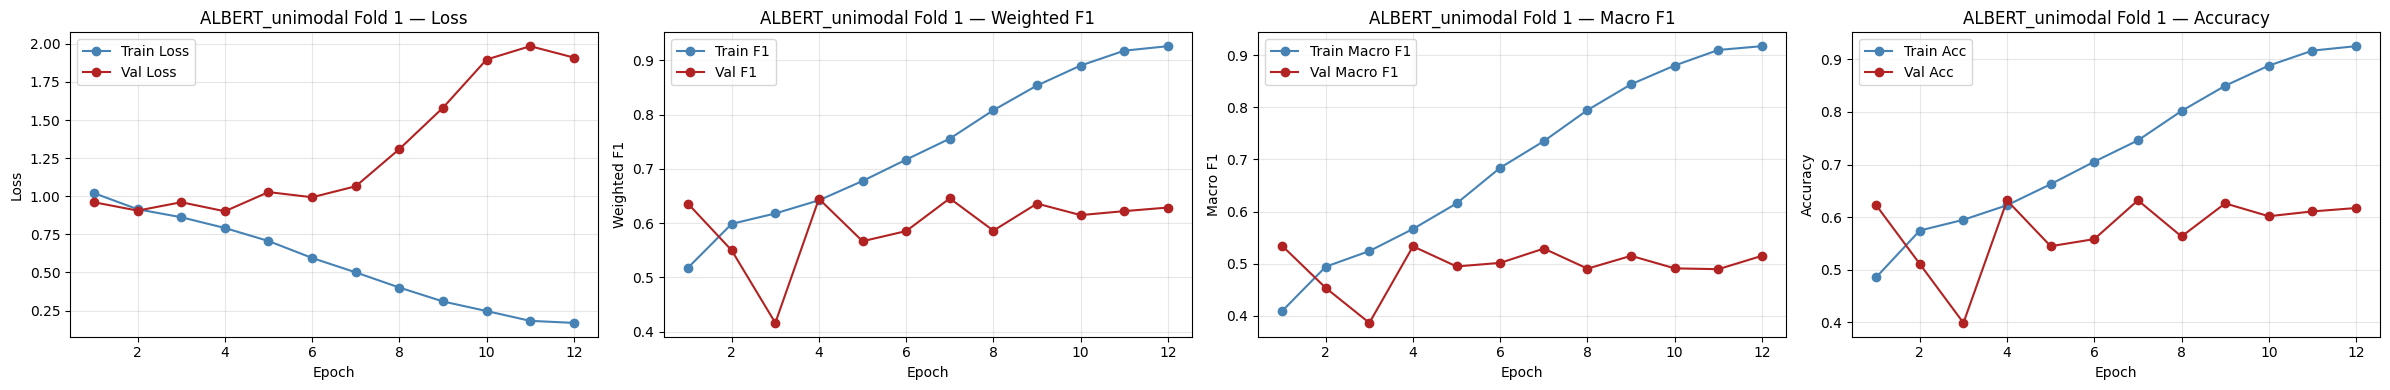


  Fold 2/5


Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

AlbertModel LOAD REPORT from: albert-base-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
predictions.LayerNorm.bias   | UNEXPECTED |  | 
predictions.dense.bias       | UNEXPECTED |  | 
predictions.dense.weight     | UNEXPECTED |  | 
predictions.bias             | UNEXPECTED |  | 
predictions.LayerNorm.weight | UNEXPECTED |  | 
predictions.decoder.bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Class counts: [9054 3527 1038] | weights=[0.501 1.287 4.373]
  -> Weighted CrossEntropy (selalu dipakai)
  Fold baru: mulai dari epoch 1


    Train:   0%|          | 0/213 [00:00<?, ?it/s]

    Val  :   0%|          | 0/54 [00:00<?, ?it/s]

... (23 outputs left out)

    Val  :   0%|          | 0/54 [00:00<?, ?it/s]

    Ep  9 | TrLoss 0.3115 TrF1 0.8510 TrMacro 0.8450 TrAcc 0.8462 | ValLoss 1.5468 ValF1 0.6136 ValMacro 0.5149 ValAcc 0.5953
    Early stopping at epoch 9 (patience=5)


    OOF  :   0%|          | 0/54 [00:00<?, ?it/s]

  Best F1: 0.6588 | Saved.


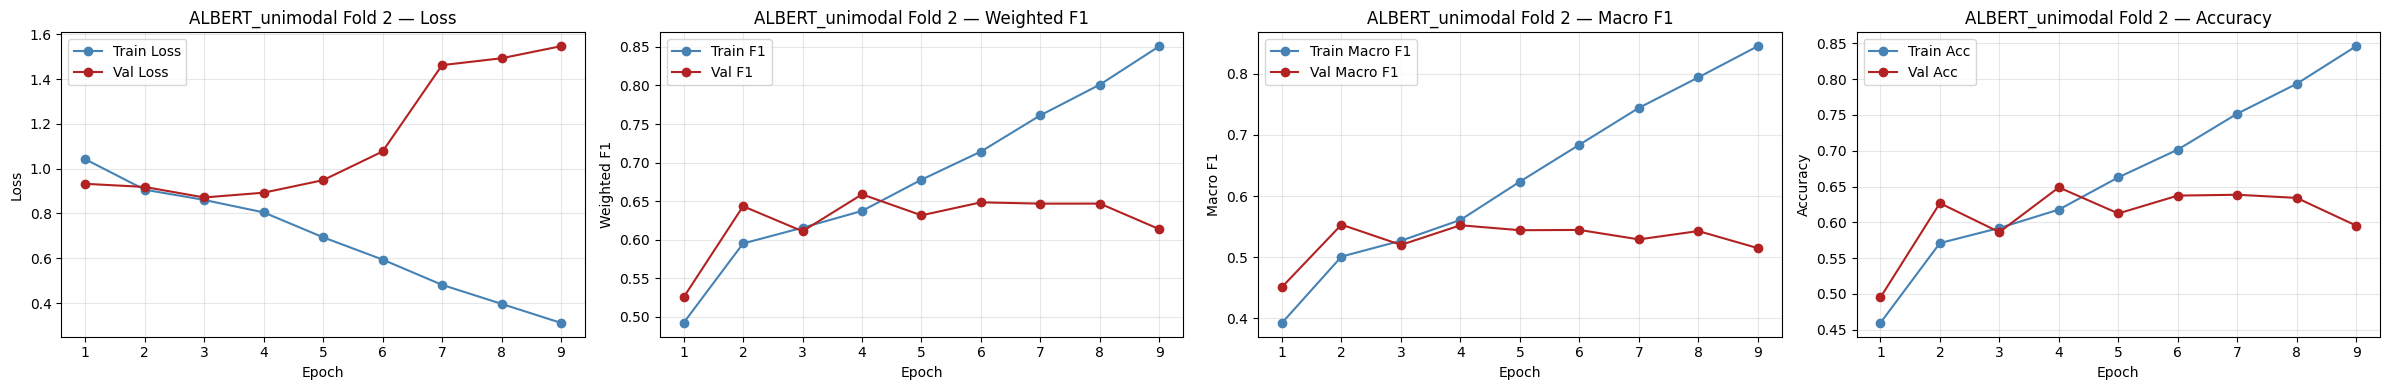


  Fold 3/5


Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

AlbertModel LOAD REPORT from: albert-base-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
predictions.LayerNorm.bias   | UNEXPECTED |  | 
predictions.dense.bias       | UNEXPECTED |  | 
predictions.dense.weight     | UNEXPECTED |  | 
predictions.bias             | UNEXPECTED |  | 
predictions.LayerNorm.weight | UNEXPECTED |  | 
predictions.decoder.bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Class counts: [9054 3527 1038] | weights=[0.501 1.287 4.373]
  -> Weighted CrossEntropy (selalu dipakai)
  Fold baru: mulai dari epoch 1


    Train:   0%|          | 0/213 [00:00<?, ?it/s]

    Val  :   0%|          | 0/54 [00:00<?, ?it/s]

... (14 outputs left out)

    Val  :   0%|          | 0/54 [00:00<?, ?it/s]

    Ep  6 | TrLoss 0.6839 TrF1 0.6864 TrMacro 0.6347 TrAcc 0.6715 | ValLoss 1.0053 ValF1 0.6253 ValMacro 0.5105 ValAcc 0.6044
    Early stopping at epoch 6 (patience=5)


    OOF  :   0%|          | 0/54 [00:00<?, ?it/s]

  Best F1: 0.6492 | Saved.


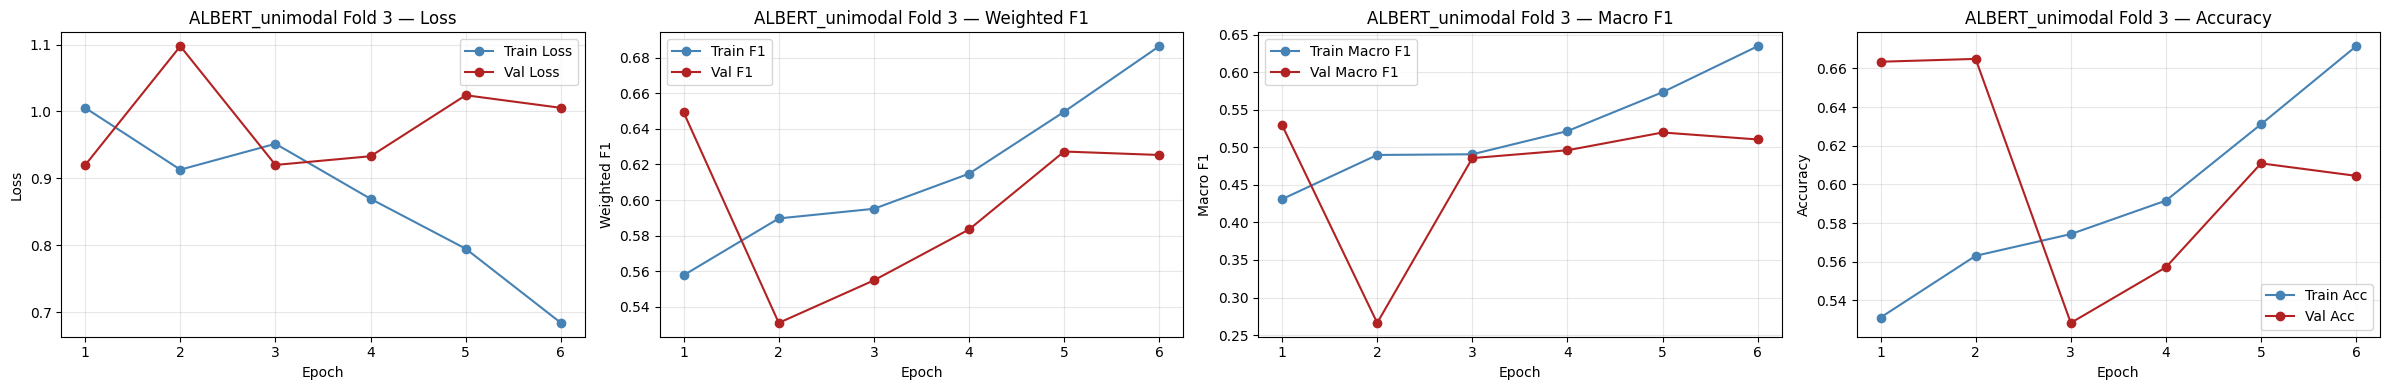


  Fold 4/5


Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

AlbertModel LOAD REPORT from: albert-base-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
predictions.LayerNorm.bias   | UNEXPECTED |  | 
predictions.dense.bias       | UNEXPECTED |  | 
predictions.dense.weight     | UNEXPECTED |  | 
predictions.bias             | UNEXPECTED |  | 
predictions.LayerNorm.weight | UNEXPECTED |  | 
predictions.decoder.bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Class counts: [9055 3526 1038] | weights=[0.501 1.287 4.373]
  -> Weighted CrossEntropy (selalu dipakai)
  Fold baru: mulai dari epoch 1


    Train:   0%|          | 0/213 [00:00<?, ?it/s]

    Val  :   0%|          | 0/54 [00:00<?, ?it/s]

... (17 outputs left out)

    Val  :   0%|          | 0/54 [00:00<?, ?it/s]

    Ep  7 | TrLoss 0.4756 TrF1 0.7688 TrMacro 0.7522 TrAcc 0.7597 | ValLoss 1.2785 ValF1 0.6098 ValMacro 0.5076 ValAcc 0.5912
    Early stopping at epoch 7 (patience=5)


    OOF  :   0%|          | 0/54 [00:00<?, ?it/s]

  Best F1: 0.6548 | Saved.


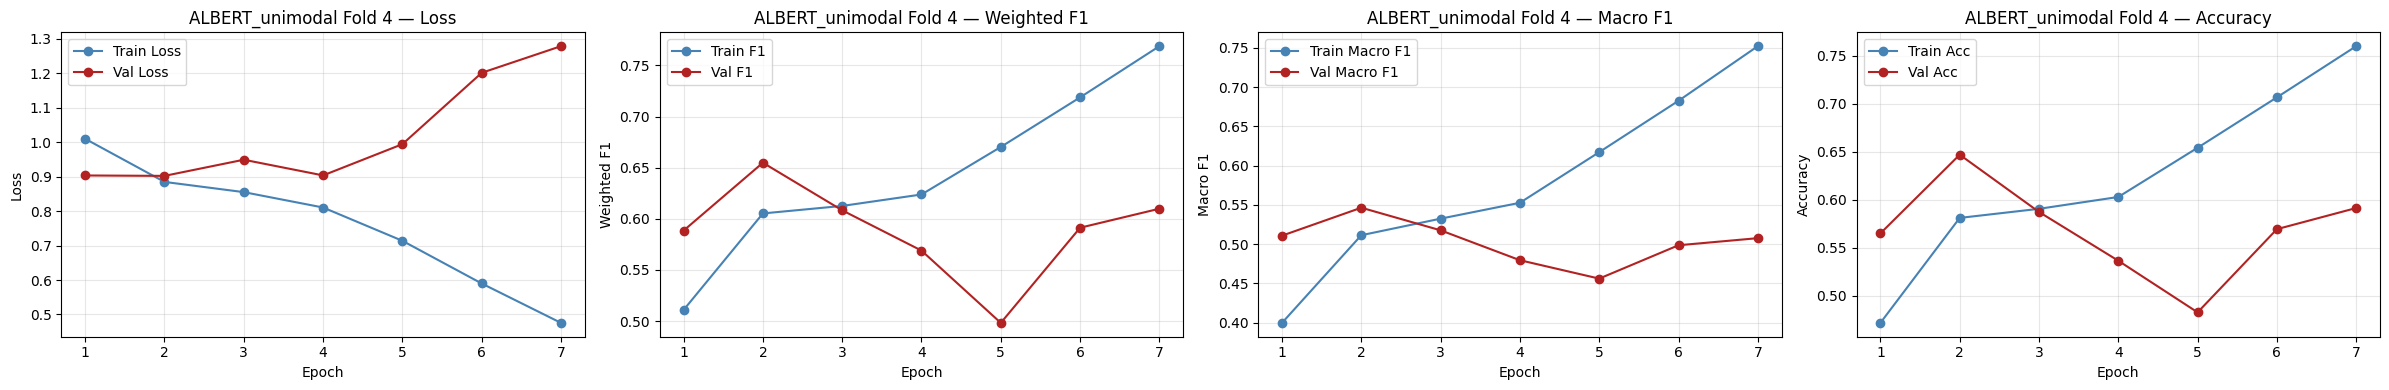


  Fold 5/5


Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

AlbertModel LOAD REPORT from: albert-base-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
predictions.LayerNorm.bias   | UNEXPECTED |  | 
predictions.dense.bias       | UNEXPECTED |  | 
predictions.dense.weight     | UNEXPECTED |  | 
predictions.bias             | UNEXPECTED |  | 
predictions.LayerNorm.weight | UNEXPECTED |  | 
predictions.decoder.bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Class counts: [9055 3526 1039] | weights=[0.501 1.288 4.37 ]
  -> Weighted CrossEntropy (selalu dipakai)
  Fold baru: mulai dari epoch 1


    Train:   0%|          | 0/213 [00:00<?, ?it/s]

    Val  :   0%|          | 0/54 [00:00<?, ?it/s]

... (26 outputs left out)

    Val  :   0%|          | 0/54 [00:00<?, ?it/s]

    Ep 10 | TrLoss 0.2289 TrF1 0.8984 TrMacro 0.8902 TrAcc 0.8962 | ValLoss 1.8750 ValF1 0.6143 ValMacro 0.5019 ValAcc 0.5958
    Early stopping at epoch 10 (patience=5)


    OOF  :   0%|          | 0/54 [00:00<?, ?it/s]

  Best F1: 0.6501 | Saved.


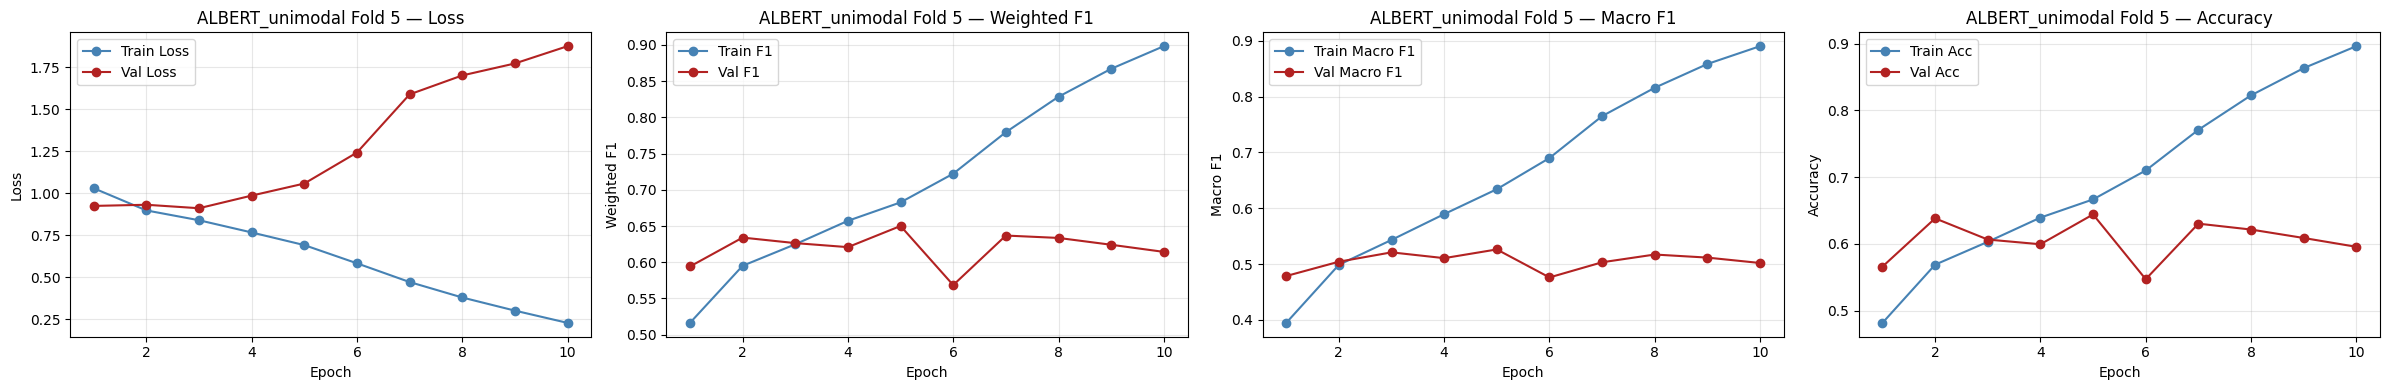


SUMMARY: ALBERT_unimodal
  loss                : 0.9676 +- 0.0773
  accuracy            : 0.6470 +- 0.0101
  precision_weighted  : 0.6634 +- 0.0085
  recall_weighted     : 0.6470 +- 0.0101
  f1                  : 0.6517 +- 0.0046
  precision_macro     : 0.5286 +- 0.0114
  recall_macro        : 0.5585 +- 0.0147
  f1_macro            : 0.5367 +- 0.0105

  [OOF] ALBERT_unimodal: N=17024 | saved: /kaggle/working/checkpoints/unimodal/albert/ALBERT_unimodal_oof.json
  [OOF] Confusion matrix (baris=true, kolom=prediksi | positive, neutral, negative):
  [[8453 2282  583]
   [1957 1923  528]
   [ 302  357  639]]
  [OOF] Laporan per kelas:
  class         prec     rec      f1     sup
  positive    0.7891  0.7469  0.7674   11318
  neutral     0.4215  0.4363  0.4288    4408
  negative    0.3651  0.4923  0.4193    1298
  macro avg   0.5253  0.5585  0.5385   17024
  weighted avg  0.6616  0.6470  0.6532   17024
  accuracy                    0.6470        


In [10]:
# -- Set seed ulang sebelum training dimulai ------------------------------------------
# Dipanggil ulang di sini (bukan hanya di awal file) agar urutan menjalankan file
# tidak memengaruhi hasil random model ini.
set_seed(Config.SEED)

# -- E1: pemanggilan training untuk ALBERT (unimodal teks) ----------------------------
results_albert, oof_albert = run_cv_text(df, "ALBERT_unimodal")

In [11]:
# -- Penyimpanan hasil: ALBERT_unimodal -------------------------------------------------
all_results = {'ALBERT_unimodal': results_albert}
all_oof = {'ALBERT_unimodal': oof_albert}

# Simpan metrik tiap fold ke JSON
out = os.path.join(Config.CHECKPOINT_DIR, 'unimodal_albert_results.json')
with open(out, 'w') as f:
    json.dump({k: [{m: float(x) for m, x in r.items()} for r in v] for k, v in all_results.items()}, f, indent=2)
print(f'Results saved: {out}')

# Tabel rata-rata lipatan: mean +- std antar 5 fold (8 metrik lengkap)
metrics = ['loss','accuracy','precision_weighted','recall_weighted','f1',
           'precision_macro','recall_macro','f1_macro']
print(f"\n{'Experiment':<22}" + ''.join(f'{m:>22}' for m in metrics))
print('-' * (22 + 22*len(metrics)))
for name, res in all_results.items():
    row = f'{name:<22}'
    for m in metrics:  # satu kolom per metrik: mean +- std
        v = [r[m] for r in res]
        row += f'{np.mean(v):.4f}±{np.std(v):.3f}'.rjust(22)
    print(row)
print('\nNote: f1 = weighted F1 (metrik early-stopping / seleksi model).')

# Bagian OOF — confusion matrix + laporan per kelas
# (mencakup seluruh dataset hasil gabungan fold, bukan rata-rata)
for name, oof in all_oof.items():
    print(f"\n{'='*70}\nOOF (full dataset, pooled folds): {name} | N={len(oof['labels'])}\n{'='*70}")
    print('Confusion matrix (baris=true, kolom=prediksi | positive, neutral, negative):')
    print(oof['confusion_matrix'])
    rep, names = oof['report'], [Config.ID2LABEL[0], Config.ID2LABEL[1], Config.ID2LABEL[2]]
    print(f"{'class':<12}{'precision':>10}{'recall':>10}{'f1':>10}{'support':>10}")
    for c in names:  # satu baris per kelas sentimen
        r = rep[c]
        print(f"{c:<12}{r['precision']:>10.4f}{r['recall']:>10.4f}{r['f1-score']:>10.4f}{r['support']:>10.0f}")
    for k in ['macro avg', 'weighted avg', 'accuracy']:  # baris rangkuman
        r = rep[k]
        if isinstance(r, dict):
            print(f"{k:<12}{r['precision']:>10.4f}{r['recall']:>10.4f}{r['f1-score']:>10.4f}{r['support']:>10.0f}")
        else:
            print(f"{k:<12}{'':>10}{'':>10}{r:>10.4f}{'':>10}")
    print(f"OOF file: {oof['oof_path']}")

print(f'\nLoss-curve plots saved to: {Config.PLOTS_DIR}')

Results saved: /kaggle/working/checkpoints/unimodal/albert/unimodal_albert_results.json

Experiment                              loss              accuracy    precision_weighted       recall_weighted                    f1       precision_macro          recall_macro              f1_macro
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
ALBERT_unimodal                 0.9676±0.077          0.6470±0.010          0.6634±0.009          0.6470±0.010          0.6517±0.005          0.5286±0.011          0.5585±0.015          0.5367±0.011

Note: f1 = weighted F1 (metrik early-stopping / seleksi model).

OOF (full dataset, pooled folds): ALBERT_unimodal | N=17024
Confusion matrix (baris=true, kolom=prediksi | positive, neutral, negative):
[[8453 2282  583]
 [1957 1923  528]
 [ 302  357  639]]
class        precision    recall        f1   support
pos